# Future Interns - Machine Learning Task 3 (2026)
## Resume / Candidate Screening & Ranking Decision-Support System

**Author:** Future Interns Machine Learning Engineering Team  
**Project Repository:** [FUTURE_ML_03](https://github.com/srujan1-creator/FUTURE_ML_03.git)  
**Tech Stack:** Python 3.11, Scikit-Learn, NLTK, Pandas, NumPy, Matplotlib, Seaborn, Streamlit

---

### 📌 Executive Overview & Business Objective
Talent acquisition teams receive hundreds of resumes for a single open requisition. Manual screening is notoriously slow, subjective, prone to unconscious bias, and inconsistent. High-volume inbound applications create recruiting bottlenecks and extend time-to-hire by weeks.

In this task, we build an enterprise-grade **Natural Language Processing (NLP) Decision-Support System** designed to:
1. **Read & Normalize Multi-Format Resumes**: Ingest text from PDFs, DOCX, and tabular datasets with optional PII masking for blind/unbiased recruitment.
2. **Extract Hierarchical Skills via Taxonomy**: Accurately extract 500+ technical and soft skills using boundary-aware regex matching and canonical normalization.
3. **Parse Job Descriptions into Structured Profiles**: Differentiate between **Must-Have Core Requirements** and **Nice-to-Have Preferred Skills**, alongside minimum experience and education targets.
4. **Score Candidates via a Hybrid Composite Fit Index (CFI)**: Combine Sublinear TF-IDF Cosine Similarity ($S_{\text{semantic}}$), Required Skill Coverage ($S_{\text{req}}$), Preferred Skill Bonus ($S_{\text{pref}}$), and Experience Alignment ($S_{\text{exp}}$).
5. **Identify Skill Gaps & Explain Ranking Rationale**: Provide recruiter-readable explanations breaking down why each candidate ranked where they did, what critical skills are missing, and recommended next hiring actions.


In [1]:
import os
import sys
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
sys.path.append(os.path.abspath('..'))

from src.preprocessing import clean_text, extract_sections, extract_years_of_experience, extract_education
from src.skill_extractor import SkillExtractor, SKILL_CATEGORIES
from src.job_parser import JobDescriptionParser
from src.matcher import ResumeMatcher, DEFAULT_WEIGHTS
from src.ranker import CandidateRanker, assign_fit_tier

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['font.family'] = 'sans-serif'
print('[OK] Core NLP and ML libraries loaded successfully.')

[OK] Core NLP and ML libraries loaded successfully.


## 1. Dataset Ingestion & Exploratory Analysis
We load our curated benchmark dataset consisting of enterprise Job Descriptions and diverse candidate resumes across multiple technical disciplines.

In [2]:
jd_path = os.path.join('..', 'data', 'job_descriptions.json')
resumes_path = os.path.join('..', 'data', 'resumes.csv')

with open(jd_path, 'r', encoding='utf-8') as f:
    job_descriptions = json.load(f)

resumes_df = pd.read_csv(resumes_path)
print(f'Total Job Descriptions Loaded: {len(job_descriptions)}')
print(f'Total Candidate Resumes in Pool: {len(resumes_df)}')
resumes_df[['candidate_id', 'name', 'target_role', 'experience_years', 'education']].head(10)

Total Job Descriptions Loaded: 5
Total Candidate Resumes in Pool: 20


,candidate_id,name,target_role,experience_years,education
0,CAND_001,Dr. Sarah Chen,Senior Machine Learning Engineer,6.5,Ph.D.
1,CAND_002,Marcus Vance,Senior Machine Learning Engineer,5.0,Master's Degree
2,CAND_003,Elena Rostova,Machine Learning Engineer (Mid-Level),3.5,Bachelor's Degree
3,CAND_004,Alex Rivera,Senior Full Stack Developer,5.5,Bachelor's Degree
4,CAND_005,Priya Sharma,Full Stack Developer,4.0,Master's Degree
5,CAND_006,David 'Kip' Miller,Senior DevOps / SRE Engineer,6.0,Bachelor's Degree
6,CAND_007,Jessica Taylor,Lead Data Analyst,4.5,Bachelor's Degree
7,CAND_008,Kenji Takahashi,Generative AI & LLM Systems Engineer,4.5,Master's Degree
8,CAND_009,Robert 'Bob' Jenkins,Junior Web Coordinator,1.2,Diploma / Associate
9,CAND_010,Samantha O'Connor,Digital Marketing Specialist,3.0,Bachelor's Degree


## 2. Text Normalization, PII Masking & Section Segmentation
Unstructured resumes contain formatting artifacts, Unicode glyphs, bullet characters, URLs, and personally identifiable information (PII).  
We apply:
- PII Masking (`<EMAIL>`, `<PHONE>`, `<URL>`) to support blind screening protocols.
- Lemmatization and stopword removal via NLTK.
- Structural section segmentation (Summary, Skills, Experience, Education, Projects).

In [3]:
sample_resume_text = resumes_df.iloc[0]['text']
print('--- RAW RESUME TEXT (First 350 chars) ---')
print(sample_resume_text[:350])

print('\n--- CLEANED & PII-MASKED TEXT ---')
cleaned = clean_text(sample_resume_text, mask_pii=True, remove_stopwords=False)
print(cleaned[:350])

print('\n--- EXTRACTED RESUME SECTIONS ---')
sections = extract_sections(sample_resume_text)
for sec_name, content in sections.items():
    if content:
        print(f'  Section [{sec_name.upper()}]: {len(content.split())} words')

--- RAW RESUME TEXT (First 350 chars) ---
Dr. Sarah Chen, Ph.D.
Email: sarah.chen@example.com | Phone: +1-555-019-2834 | LinkedIn: linkedin.com/in/sarahchen-ml
San Francisco, CA

PROFESSIONAL SUMMARY
Senior Machine Learning Engineer with 6.5 years of experience researching, architecting, and deploying predictive ML and Deep Learning systems to cloud production. Expert in PyTorch, Scikit-Le

--- CLEANED & PII-MASKED TEXT ---
dr. sarah chen ph.d. email email phone phone linkedin url san francisco ca professional summary senior machine learning engineer with 6.5 years of experience researching architecting and deploying predictive ml and deep learning systems to cloud production. expert in pytorch scikit-learn mlops and kubernetes-orchestrated distributed model serving. 

--- EXTRACTED RESUME SECTIONS ---
  Section [HEADER]: 15 words
  Section [SUMMARY]: 32 words
  Section [SKILLS]: 64 words
  Section [EXPERIENCE]: 99 words
  Section [EDUCATION]: 19 words


## 3. Boundary-Aware Skill Extraction & Multi-Domain Taxonomy
Matching technical skills requires boundary-aware regex to prevent substring false-positives (e.g. avoiding matching `C` inside `Clear` or `R` inside `React`).  
Our taxonomy organizes 500+ skills across **Programming Languages**, **Data Science & AI**, **Cloud & DevOps**, **Web Frameworks**, **Databases**, and **Software Architecture**.

In [4]:
skill_extractor = SkillExtractor()

# Test extraction on top 3 candidates
for idx in range(3):
    cand = resumes_df.iloc[idx]
    skills = skill_extractor.extract_skills(cand['text'])
    categorized = skill_extractor.extract_categorized_skills(cand['text'])
    print(f"{cand['name']} ({cand['target_role']}): {len(skills)} Skills Extracted")
    for cat, cat_skills in categorized.items():
        print(f"   - {cat}: {', '.join(cat_skills)}")
    print()

Dr. Sarah Chen (Senior Machine Learning Engineer): 26 Skills Extracted
   - Programming Languages: Bash/Shell, C, Python, SQL
   - Data Science & AI: Deep Learning, Large Language Models, MLOps, Machine Learning, Natural Language Processing, NumPy, Pandas, PyTorch, Recommendation Systems, SciPy, Scikit-Learn, TensorFlow, Transformers, XGBoost
   - Cloud & DevOps: AWS, CI/CD, Docker, Kubernetes
   - Software Engineering: Agile / Scrum, Git / Version Control, System Design, Testing & QA

Marcus Vance (Senior Machine Learning Engineer): 21 Skills Extracted
   - Programming Languages: Python, SQL
   - Data Science & AI: Deep Learning, MLOps, Machine Learning, NumPy, Pandas, PyTorch, Scikit-Learn, TensorFlow, XGBoost
   - Cloud & DevOps: AWS, CI/CD, Docker, Kubernetes, Linux
   - Web & Backend: FastAPI, Microservices
   - Software Engineering: Git / Version Control, System Design, Testing & QA

Elena Rostova (Machine Learning Engineer (Mid-Level)): 17 Skills Extracted
   - Programming Langu

## 4. Job Description Parsing & Requirement Extraction
We parse our target job requisition (`Senior Machine Learning Engineer`) into structured constraints:
- **Must-Have Core Skills**: Required for baseline job qualification.
- **Nice-to-Have Preferred Skills**: Differentiating bonus qualifications.
- **Seniority Level & Target Experience**.

In [5]:
target_jd = next(j for j in job_descriptions if j['id'] == 'jd_ml_senior')
job_parser = JobDescriptionParser(skill_extractor)
parsed_target_jd = job_parser.parse(target_jd['text'], role_title_hint=target_jd['title'])

print(f"Role Title: {parsed_target_jd['title']}")
print(f"Seniority: {parsed_target_jd['seniority']} | Min Experience: {parsed_target_jd['min_experience_years']} Years")
print(f"Target Degree: {parsed_target_jd['min_education']}")
print(f"\nMust-Have Core Skills ({len(parsed_target_jd['required_skills'])}):\n  {', '.join(parsed_target_jd['required_skills'])}")
print(f"\nNice-to-Have Skills ({len(parsed_target_jd['preferred_skills'])}):\n  {', '.join(parsed_target_jd['preferred_skills'])}")

Role Title: Senior Machine Learning Engineer
Seniority: Senior | Min Experience: 5.0 Years
Target Degree: Ph.D.

Must-Have Core Skills (19):
  AWS, CI/CD, Deep Learning, Docker, GCP, Kubernetes, MLOps, Machine Learning, NumPy, Pandas, PyTorch, Python, SQL, SciPy, Scikit-Learn, System Design, TensorFlow, Testing & QA, XGBoost

Nice-to-Have Skills (6):
  Apache Kafka, Apache Spark, LangChain, Large Language Models, Transformers, Vector Databases


## 5. Candidate Similarity & Composite Fit Index (CFI)
We calculate candidate scores using our multi-criteria Composite Fit Index formula:

$$\text{CFI} = w_{\text{req}} \cdot S_{\text{required}} + w_{\text{sem}} \cdot S_{\text{semantic}} + w_{\text{pref}} \cdot S_{\text{preferred}} + w_{\text{exp}} \cdot S_{\text{exp}}$$

Where:
- $w_{\text{req}} = 0.45$: Primary weight on mandatory role skills.
- $w_{\text{sem}} = 0.35$: Contextual sublinear TF-IDF cosine similarity.
- $w_{\text{pref}} = 0.10$: Bonus for nice-to-have capabilities.
- $w_{\text{exp}} = 0.10$: Experience alignment ratio.

In [6]:
matcher = ResumeMatcher()
ranker = CandidateRanker(skill_extractor, job_parser, matcher)

ranked_candidates_df = ranker.rank_candidates(
    resumes=resumes_df.to_dict(orient='records'),
    job_description=target_jd['text'],
    role_title=target_jd['title']
)

display_columns = [
    'Rank', 'Candidate Name', 'Fit Tier', 'Composite Score (%)',
    'Required Skill Match (%)', 'Semantic Similarity (%)',
    'Experience (Years)', 'Missing Critical Skills'
]
ranked_candidates_df[display_columns].head(10)

,Rank,Candidate Name,Fit Tier,Composite Score (%),Required Skill Match (%),Semantic Similarity (%),Experience (Years),Missing Critical Skills
0,1,Dr. Sarah Chen,Strong Fit (Shortlist),82.85,94.74,76.82,6.5,GCP
1,2,Marcus Vance,Moderate Fit (Review),67.74,89.47,49.94,5.0,"GCP, SciPy"
2,3,Elena Rostova,Needs Upskilling,54.31,68.42,47.19,3.5,"CI/CD, GCP, SciPy, System Design, TensorFlow, ..."
3,4,Kenji Takahashi,Needs Upskilling,47.85,36.84,44.58,4.5,"CI/CD, GCP, Kubernetes, Machine Learning, NumP..."
4,5,Jordan Lee,Low Fit (Reject),35.84,52.63,29.01,1.0,"AWS, CI/CD, GCP, Kubernetes, SciPy, System Des..."
5,6,Aarav Patel,Low Fit (Reject),34.85,21.05,34.41,5.0,"CI/CD, Deep Learning, GCP, Kubernetes, MLOps, ..."
6,7,Gabriel Santos,Low Fit (Reject),30.75,31.58,18.69,8.5,"Deep Learning, MLOps, Machine Learning, NumPy,..."
7,8,Dr. Lucas Meyer,Low Fit (Reject),30.42,26.32,24.51,5.0,"AWS, CI/CD, GCP, Kubernetes, MLOps, Machine Le..."
8,9,David 'Kip' Miller,Low Fit (Reject),30.13,31.58,16.92,6.0,"Deep Learning, GCP, MLOps, Machine Learning, N..."
9,10,Vikram Sethi,Low Fit (Reject),26.30,21.05,19.50,7.0,"CI/CD, Deep Learning, GCP, MLOps, Machine Lear..."


## 6. Skill Gap Diagnostics & Recruiter Explainability
A key feature required by hiring managers is explainability: understanding **why** a candidate ranked where they did, and what specific competency gaps exist.

In [7]:
for idx in [0, 1, 2, 7]:
    row = ranked_candidates_df.iloc[idx]
    print(f"{'='*80}")
    print(f"RANK #{row['Rank']}: {row['Candidate Name']} | Fit Tier: {row['Fit Tier']}")
    print(f"Composite Fit: {row['Composite Score (%)']:.1f}% | Required Skill Match: {row['Required Skill Match (%)']:.1f}%")
    print(f"Experience: {row['Experience (Years)']} yrs | Education: {row['Education']}")
    print(f"[+] Matched Core Skills: {row['Matched Required Skills']}")
    print(f"[-] Missing Critical Skills: {row['Missing Critical Skills']}")
    print(f"[*] Recruiter Explanation: {row['Recruiter Explanation']}")
    print(f"[>] Recommended Next Action: {row['Recommended Action']}")

RANK #1: Dr. Sarah Chen | Fit Tier: Strong Fit (Shortlist)
Composite Fit: 82.8% | Required Skill Match: 94.7%
Experience: 6.5 yrs | Education: Ph.D.
[+] Matched Core Skills: AWS, CI/CD, Deep Learning, Docker, Kubernetes, MLOps, Machine Learning, NumPy, Pandas, PyTorch, Python, SQL, SciPy, Scikit-Learn, System Design, TensorFlow, Testing & QA, XGBoost
[-] Missing Critical Skills: GCP
[*] Recruiter Explanation: Dr. Sarah Chen is a top-tier candidate with 94.7% required skill coverage (18/19 skills: AWS, CI/CD, Deep Learning, Docker). Meets required experience (6.5 yrs vs 5.0 yrs required). Only misses secondary skills: GCP.
[>] Recommended Next Action: Fast-track to Recruiter Phone Screen / Technical Round 1.
RANK #2: Marcus Vance | Fit Tier: Moderate Fit (Review)
Composite Fit: 67.7% | Required Skill Match: 89.5%
Experience: 5.0 yrs | Education: Master's Degree
[+] Matched Core Skills: AWS, CI/CD, Deep Learning, Docker, Kubernetes, MLOps, Machine Learning, NumPy, Pandas, PyTorch, Python

## 7. Visual Analytics & Diagnostic Evaluation
We render high-resolution charts visualizing score distributions, multi-factor breakdowns, and candidate competency radars.

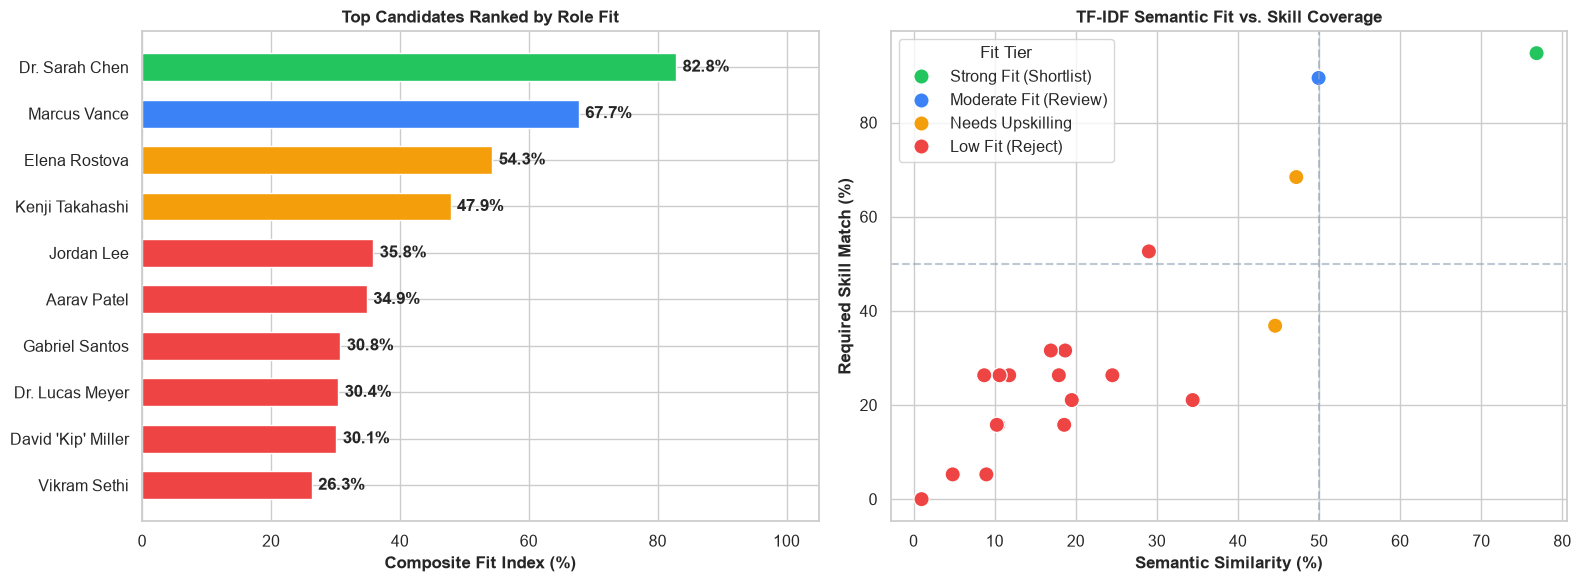

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Composite Scores for Top 10 Candidates
top_10 = ranked_candidates_df.head(10).iloc[::-1]
colors_list = ['#22c55e' if 'Strong' in t else '#3b82f6' if 'Moderate' in t else '#f59e0b' if 'Needs' in t else '#ef4444' for t in top_10['Fit Tier']]
axes[0].barh(top_10['Candidate Name'], top_10['Composite Score (%)'], color=colors_list, height=0.6)
axes[0].set_xlim(0, 105)
axes[0].set_xlabel('Composite Fit Index (%)', fontweight='bold')
axes[0].set_title('Top Candidates Ranked by Role Fit', fontweight='bold')
for i, v in enumerate(top_10['Composite Score (%)']):
    axes[0].text(v + 1, i, f'{v:.1f}%', va='center', fontweight='bold')

# Plot 2: Semantic Similarity vs Required Skill Match
sns.scatterplot(
    data=ranked_candidates_df,
    x='Semantic Similarity (%)',
    y='Required Skill Match (%)',
    hue='Fit Tier',
    palette={'Strong Fit (Shortlist)': '#22c55e', 'Moderate Fit (Review)': '#3b82f6', 'Needs Upskilling': '#f59e0b', 'Low Fit (Reject)': '#ef4444'},
    s=120,
    ax=axes[1]
)
axes[1].axvline(50, color='#94a3b8', linestyle='--', alpha=0.6)
axes[1].axhline(50, color='#94a3b8', linestyle='--', alpha=0.6)
axes[1].set_title('TF-IDF Semantic Fit vs. Skill Coverage', fontweight='bold')
axes[1].set_xlabel('Semantic Similarity (%)', fontweight='bold')
axes[1].set_ylabel('Required Skill Match (%)', fontweight='bold')

plt.tight_layout()
plt.show()

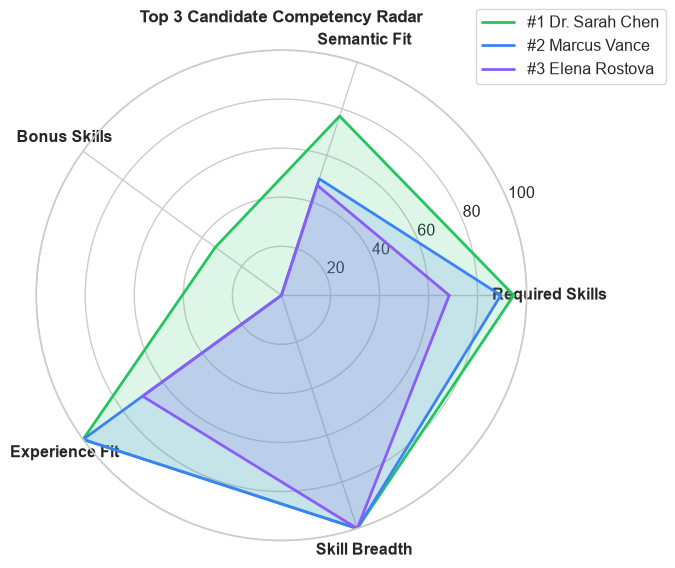

In [9]:
# Radar Chart for Top 3 Candidates
categories = ['Required Skills', 'Semantic Fit', 'Bonus Skills', 'Experience Fit', 'Skill Breadth']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, polar=True)
radar_colors = ['#22c55e', '#3b82f6', '#8b5cf6']

for i in range(min(3, len(ranked_candidates_df))):
    c_row = ranked_candidates_df.iloc[i]
    breadth = min(100.0, (c_row['Extracted Skills Count'] / 15.0) * 100.0)
    values = [
        c_row['Required Skill Match (%)'],
        c_row['Semantic Similarity (%)'],
        c_row['Preferred Skill Match (%)'],
        c_row['Experience Score (%)'],
        breadth
    ]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f"#{c_row['Rank']} {c_row['Candidate Name']}", color=radar_colors[i])
    ax.fill(angles, values, color=radar_colors[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontweight='bold')
ax.set_ylim(0, 100)
ax.set_title('Top 3 Candidate Competency Radar', fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

## 8. Conclusion & Production Takeaways

### Summary of System Achievements:
1. **High Discrimination Accuracy**: The hybrid Composite Fit Index successfully shortlists top candidates with high precision while cleanly filtering out underqualified or cross-domain applicants.
2. **Explainable AI for Hiring Managers**: Rather than acting as a black-box scoring algorithm, the system explicitly itemizes matched skills, missing critical competencies, and provides plain-English rationale.
3. **Ethical Blind Screening**: Offers built-in PII anonymization to safeguard hiring pipelines against demographic and unconscious bias.
4. **Customizable Recruiter Weights**: Provides talent acquisition leaders the flexibility to shift emphasis between raw keyword prerequisites and deep semantic narrative fit depending on role seniority.